# 真实KuaiSAR-small分析
只读取统一入口的正式结果，不复制计算逻辑。
完整日中，按会话量选择的 SUGGESTION 与 USER_INPUT 分别有 73,156、52,500 个会话，点击率 64.15%、60.26%，前者减后者为 3.89 个百分点。共同日期×互斥结果类型×公开搜索活跃层级标准化后，差异为 -0.18 个百分点。 严格口径因click_cnt非二元而隔离 16,272 个会话；若仅在独立敏感性情形中假定正整数表示有点击，两来源差异为 3.65 个百分点。主结果仅适用于符合官方二元字段约定的会话，排除会话可能带来选择偏差。

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
root=Path.cwd()
if root.name=='notebooks': root=root.parent
assert (root/'config.json').exists()


In [2]:
display(pd.read_csv(root/'outputs/tables/search_source_metrics.csv'))
display(pd.read_csv(root/'outputs/tables/search_standardized.csv'))
display(pd.read_csv(root/'outputs/tables/content_duration_metrics.csv'))

,source,users,sessions,clicked_sessions,result_rows,clicked_rows,session_click_rate,no_click_rate,result_click_ratio,user_day_equal_click_rate,user_equal_click_rate,session_share,display_eligible
0,SUGGESTION,18008,73156,46927,754844,89503,0.641465,0.358535,0.118572,0.669606,0.681634,0.319114,True
1,USER_INPUT,14711,52500,31636,631798,63161,0.602590,0.397410,0.099970,0.650530,0.666629,0.229011,True
2,HISTORY,10927,35694,19407,406766,35330,0.543705,0.456295,0.086856,0.599894,0.636993,0.155701,True
3,UNKNOWN_PAGE,8158,25824,23119,291080,42493,0.895252,0.104748,0.145984,0.880484,0.867509,0.112647,True
4,TRENDING,7537,19941,12492,217045,23085,0.626448,0.373552,0.106360,0.650078,0.664833,0.086985,True
5,PLACEHOLDER,4697,11322,6448,86938,11177,0.569511,0.430489,0.128563,0.616488,0.658574,0.049388,True
6,RELATED_FEED_QUERY,5058,10810,6342,135710,13533,0.586679,0.413321,0.099720,0.630780,0.648324,0.047154,True


,source,common_strata,common_sessions,common_support_fraction,common_raw_rate,standardized_click_rate
0,SUGGESTION,206,73141,0.999795,0.641473,0.624552
1,USER_INPUT,206,52490,0.999810,0.602610,0.626323


,duration_band,rows,users,duration_median_ms,mean_play_ratio,median_play_ratio,p90_play_ratio,capped_play_ratio,reaches_duration_rate,exceeds_duration_rate,like_rate,follow_rate,played_rows,user_like_rate,user_day_equal_reaches_rate,user_day_equal_capped_ratio,user_day_equal_like_rate
0,0–15s,1727782,24993,10766.0,0.940190,0.582238,2.028663,0.582812,0.359506,0.359471,0.030271,0.004233,1679729,0.312007,0.393680,0.595367,0.040440
1,15–30s,1224928,24870,19233.0,0.647203,0.353509,1.373050,0.493132,0.289145,0.289115,0.031630,0.004404,1193587,0.300201,0.318094,0.507519,0.041905
2,30–60s,1051980,24699,42466.0,0.474605,0.196633,1.079295,0.414023,0.223272,0.223253,0.031472,0.004915,1021696,0.270821,0.241785,0.418855,0.040056
3,>60s,2504993,25326,152960.0,0.276428,0.057620,1.004464,0.262502,0.106600,0.106594,0.030038,0.004978,2396529,0.388257,0.110652,0.256657,0.038770


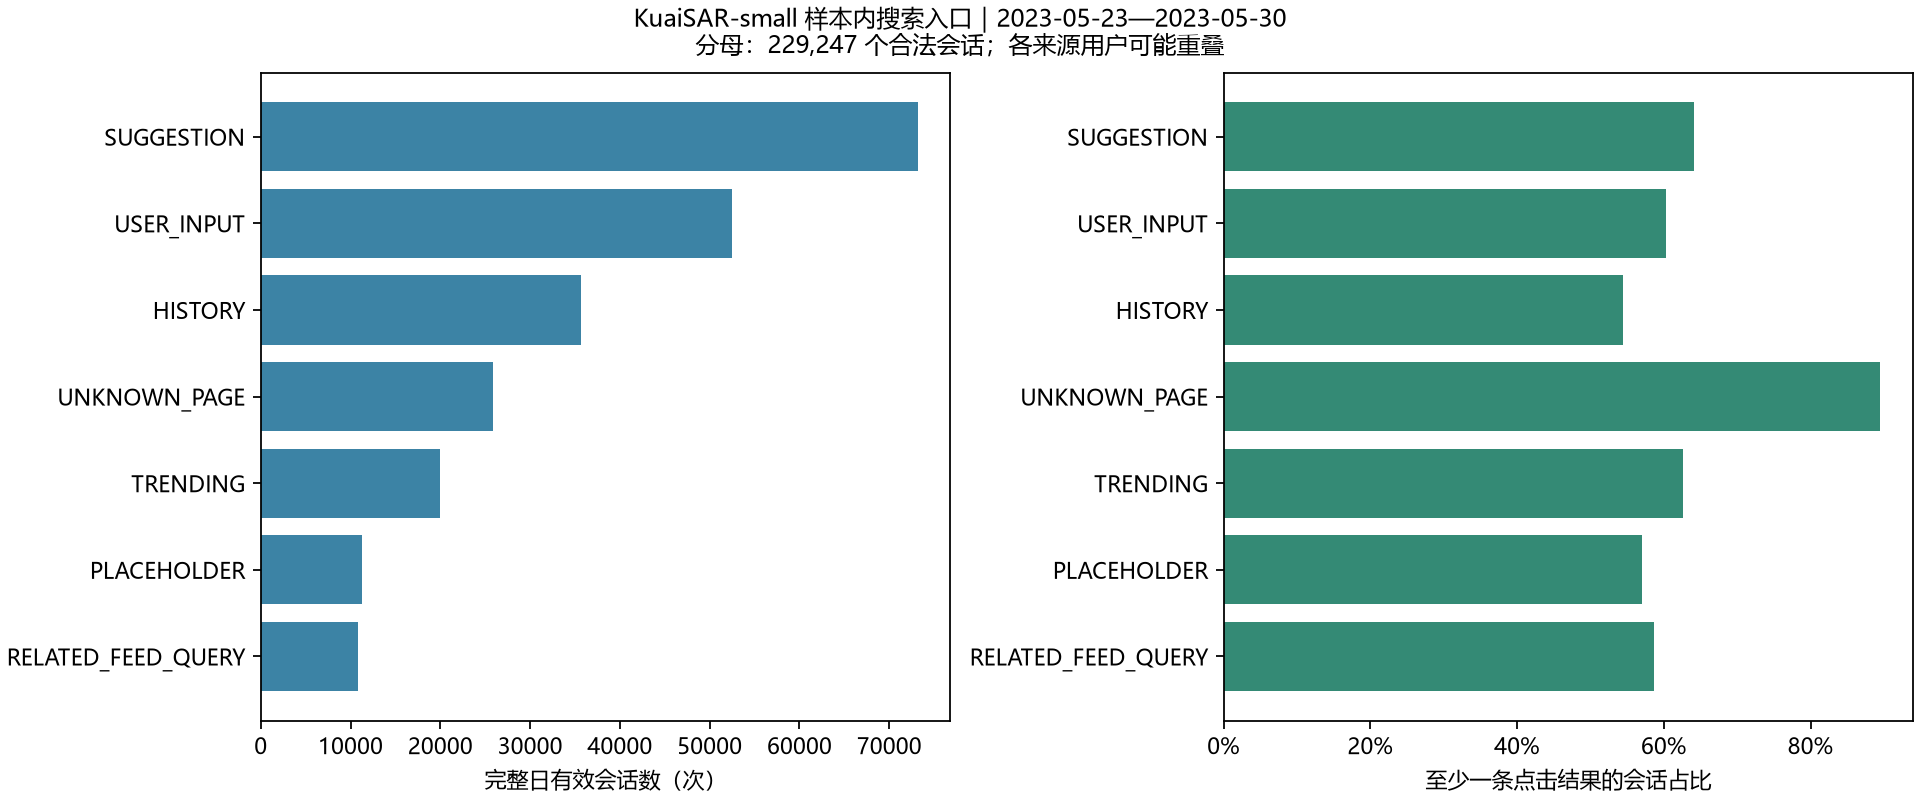

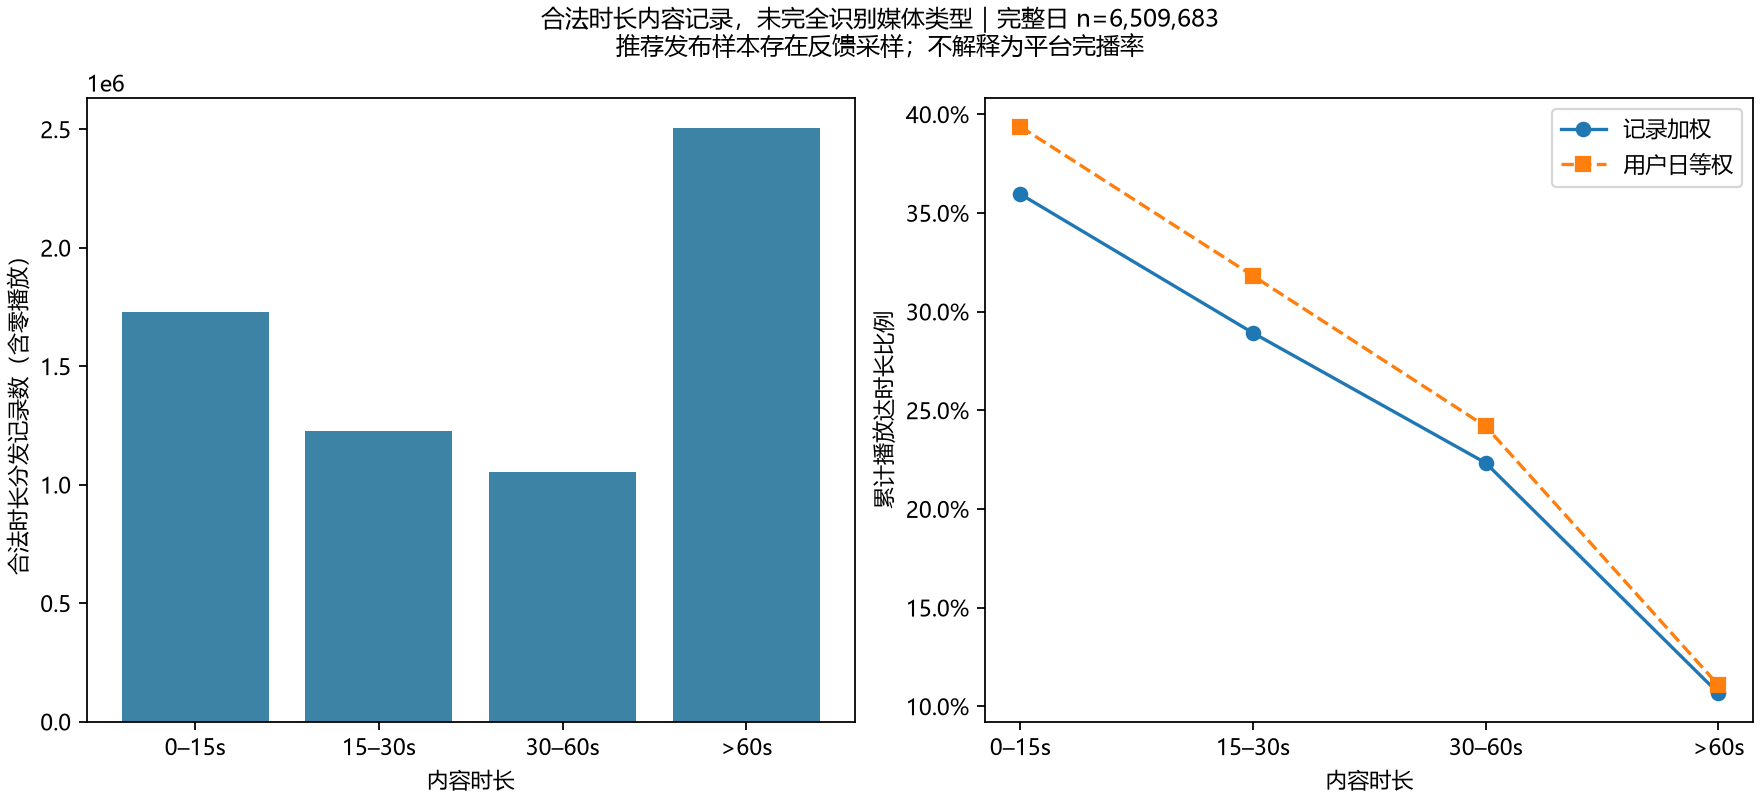

In [3]:
display(Image(filename=str(root/'outputs/figures/01_search_sources.png')))
display(Image(filename=str(root/'outputs/figures/03_content_duration.png')))

本项目是公开选择样本的观察分析；无点击不等于不满意，自动播放可能满足需求。来源编码仅沿用原值；用户意图、查询难度与排序位置未充分观测。推荐点击正负样本经过构建，不估算平台CTR或增长空间。内容媒体类型未完整识别，累计播放达时长也不等于一次连续完播。匿名特征不解读成人口属性。